In [3]:
!pip -q install "https://github.com/conda-incubator/condacolab/archive/main.zip"

import condacolab

condacolab.install(
    python_version="3.12",
    dependencies={
        "kwant": "*",
        "numpy": "*",
        "scipy": "*",
        "matplotlib": "*"
    }
)

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
📝 Writing pixi.toml...
📦 Installing...
✨ Last touches...
⏲ Done in 0:00:30
✅ Done! Restarting kernel...
ℹ️ [INFO]
  Once the session reconnects, you will be running a new Python v3.12.
  You can install new packages by running pixi in new cells like this:
    !pixi add <name>


/bin/bash: line 1: pixi: command not found


In [1]:
import kwant
import numpy as np
import scipy
import matplotlib.pyplot as plt
kwant.plotter.set_engine('matplotlib')

/content/.pixi/envs/default/lib/python3.12/site-packages/kwant/_plotter.py:77: RuntimeWarning: plotly is not available, if other engines are unavailable, only iterator-providing functions will work
  warnings.warn("plotly is not available, if other engines are unavailable,"


In [2]:
def dos_kernel_polynomial(H, syst):

    R = 5

    Emax, _  = scipy.sparse.linalg.eigsh(H, k=1, which='LA', return_eigenvectors=True)
    Emin, _  = scipy.sparse.linalg.eigsh(H, k=1, which='SA', return_eigenvectors=True)

    corr = 1/R

    a = (Emax - Emin)/(2 - corr)
    b = (Emax + Emin)/2

    H_Tilde = (H - b*np.identity(H.shape[0])) / a

    #print(Emax, Emin)
    #chebyshev basis

    def Cheb_moment(r, H, n):
        T0 = r
        T1 = H @ r

        mu = np.zeros(n)

        mu[0] = np.vdot(r, T0).real

        if(n > 1):
            mu[1] = np.vdot(r,T1).real

        for i in range(2, n):
            Tn = 2 * (H @ T1) - T0
            mu[i] = np.vdot(r, Tn).real
            T0 = T1
            T1 = Tn

        return mu

    def kernel_jackson(D):
        n = np.arange(D)
        return ((D - n + 1) * np.cos(np.pi * n /(D + 1))+ np.sin(np.pi * n / (D + 1)) / np.tan(np.pi /(D + 1))) / (D + 1)

    #random vectors

    D = syst.graph.num_nodes * 2

    Trace = 0

    B = np.identity(D)
    moments = np.zeros(D)

    #print(B.shape)
    for i in range(R):
        E = np.random.normal(size = D) * np.pi
        r = np.dot(B, np.array((np.cos(E) + np.sin(E)*1j)))
        moments += Cheb_moment(r, H_Tilde, D)

    moments = kernel_jackson(D) * moments / R



    nE = 8 * D

    E_ = np.linspace(Emin, Emax, nE).ravel()
    X_ = ((E_ - b) / a).ravel()
    X_ = np.clip(X_, -1 + 1e-12, 1 - 1e-12)

    dos = np.zeros_like(X_)
    n = len(moments)
    for i in range(n - 3):
        dos += moments[i] * np.cos(i * np.arccos(X_))

    dos = dos/(np.pi * np.sqrt(1 - X_**2))

    dos = np.abs(dos)
    return X_ , dos
    #print(np.trace(H))
    #print(moments)

In [48]:
import scipy as sp

def random_vec(len):
    v = np.random.normal(size = len) + np.random.normal(size = len) * 1j
    norm = np.linalg.norm(v)

    return v / norm

def chebyshev_values(x, n):
    T = [1, x]

    for i in range(1, n):
        T_next = 2*x*T[i] - T[i-1]
        T.append(T_next)

    return T

def chebyshev_cosine(x, n):
    return np.cos(n * np.arccos(x))


def fermi(x):

    B = 10
    E0 = 0
    return 1  / (np.exp((x - E0)*B) + 1)

def alpha_n_integral(n, a = 100):

  if n == 0:
      dn = 1.0
  else:
      dn = 2.0

  dx = 2.0 / a
  x = -1.0 + (np.arange(a) + 0.5) * dx



  alpha_vec = dn * chebyshev_cosine(-x, n) * fermi((x)) / (np.pi * np.sqrt(1 - x)**2)
  return alpha_vec

def beta_n_integral(n, a = 100):

  if n == 0:
      dn = 1.0
  else:
      dn = 2.0


  dx = 2.0 / a
  x = -1.0 + (np.arange(a) + 0.5) * dx

  alpha_vec = dn * chebyshev_cosine(x, n) * fermi(x) / (np.pi * np.sqrt(1 - x**2))
  return alpha_vec

def convolve_ab(n, m, omega, a_points=2048):
  dx = 2.0 / a_points
  x = -1.0 + (np.arange(a_points) + 0.5) * dx

  alpha = alpha_n_integral(n, a=a_points)
  beta = beta_n_integral(m, a=a_points)

  gamma = sp.signal.fftconvolve(
      alpha, beta, mode="full"
  ) * dx

  # Energy coordinates of the full convolution
  x_conv = 2.0 * x[0] + np.arange(2 * a_points - 1) * dx

  return np.interp(
      -omega, x_conv, gamma, left=0.0, right=0.0
  )

def jackson_kernel(N, n):
    theta = np.pi * n / (N + 1)
    return (
        (N - n + 1) * np.cos(theta)
        + np.sin(theta) / np.tan(np.pi / (N + 1))
    ) / (N + 1)

def kernel_polynomial_2_optical(H, syst, V, omega, n=20, norbs=1, R=10):

    Emax, _  = scipy.sparse.linalg.eigsh(H, k=1, which='LA', return_eigenvectors=True)
    Emin, _  = scipy.sparse.linalg.eigsh(H, k=1, which='SA', return_eigenvectors=True)

    corr = 1/R

    a = (Emax - Emin)/(2 - corr)
    b = (Emax + Emin)/2

    D = syst.graph.num_nodes * norbs

    H_Tilde = (H - b*np.identity(H.shape[0])) / a

    full_sum = 0

    conv_matrix = {}

    for i in range(n + 1):
        for j in range(n + 1):
            conv_matrix[(i, j)] = convolve_ab(i, j, omega = omega)

    for vecs_iter in range(R):
        #T(x)
        #approximate with T = 0


        #T(H)
        r = random_vec(D)
        r_L = V @ r
        T0_R = r
        T1_R = H_Tilde @ r
        sum = 0

        T0_L = r_L
        T1_L = H_Tilde @ r_L

        L_moments = [T0_L]
        R_moments = [T0_R]

        for i in range(n):

            R_moments.append(T1_R)
            temp = T1_R
            T1_R = 2* (H_Tilde @ T1_R) - T0_R
            T0_R = temp

        for i in range(n):
            L_moments.append(T1_L)

            temp = T1_L
            T1_L = 2* (H_Tilde @ T1_L) - T0_L
            T0_L = temp


        for i in range(n + 1):
            for j in range(n + 1):
                sum += conv_matrix[(i, j)] * np.vdot(L_moments[j], V @ R_moments[i]) * jackson_kernel(n, i) * jackson_kernel(n, j)


    return sum / R, Emax, Emin





In [49]:
#pauli matrices

sigma_x = np.array([[0, 1], [1, 0]])
sigma_y = np.array([[0, -1j], [1j, 0]])
sigma_z = np.array([[1, 0], [0, -1]])

In [54]:
dE_ = []
x_ = []
curr_ = []

R = 5

def onsite(site, mu):
    # get the position of the site
    x, y = site.pos
    return mu * sigma_z

rng = np.random.default_rng(seed = 40)




def hopping(site1, site2, t0):
    return t0 * np.identity(2)

def shape(site):
    x, y, = site.pos

    return x*x + y*y < R*R

template = kwant.Builder(kwant.TranslationalSymmetry(*np.identity(2)))

lat = kwant.lattice.square(norbs = 2)

template[lat(0,0)] = onsite

template[lat(0, 0), lat(0,1)] = hopping
template[lat(0, 0), lat(1,0)] = hopping
print(type(lat(0, 0)))

syst = kwant.Builder()
syst.fill(template, shape, (0,0));

Bloch = kwant.wraparound.wraparound(template, keep = None)
Bloch = Bloch.finalized()

syst = syst.finalized()

mu = 6
t0 = 1
tr = 0.5


params_with_perturbation = { 'mu': mu, 't0' : t0}
H_total = syst.hamiltonian_submatrix(sparse=False, params=params_with_perturbation)

params_without_perturbation = { 'mu': mu, 't0' : t0 }
H_0 = syst.hamiltonian_submatrix(sparse=False, params=params_without_perturbation)

epsilon_x = 0.1

num_sites = syst.graph.num_nodes

V = np.kron(
    np.eye(num_sites, dtype=complex),
    epsilon_x * sigma_x
)

w= np.linspace((-2 + 1e-12), 2 - 1e-12, 1001)

opt_0, Emax_1, Emin_1 = kernel_polynomial_2_optical(H_total, syst, V, omega = w ,n = 20, norbs = 2, R = 100)
opt, Emax_2, Emin_2 = kernel_polynomial_2_optical(H_total, syst, V, omega = w, n = 20, norbs = 2, R = 100)


<class 'kwant.builder.Site'>


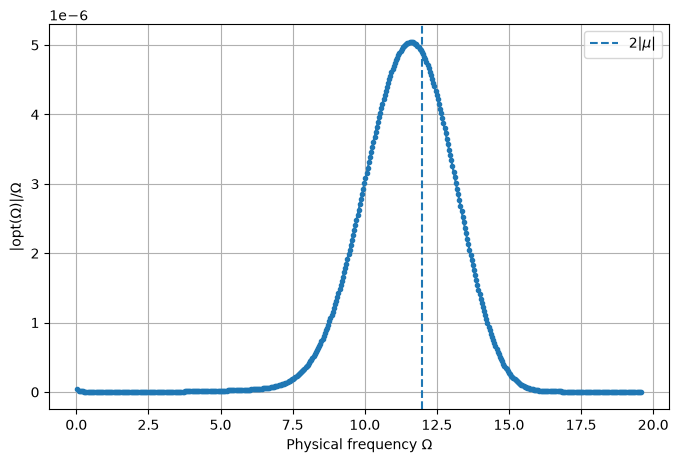

In [55]:
R_avg = 500

Emax = Emax_1

Emin = Emin_1

a = (Emax - Emin) / (2 - 1 / R_avg)

w_scaled = w

w_physical = a * w_scaled



mask = w_physical > 1e-12

plt.figure(figsize=(8, 5))
plt.plot(
    w_physical[mask],
    np.abs(opt[mask]) / w_physical[mask],
    ".-"
)

plt.axvline(2 * abs(mu), linestyle="--", label=r"$2|\mu|$")
plt.xlabel(r"Physical frequency $\Omega$")
plt.ylabel(r"$|\mathrm{opt}(\Omega)|/\Omega$")
plt.grid()
plt.legend()
plt.show()


In [61]:
dE_ = []
x_ = []
curr_ = []

R = 5

def onsite(site, mu):
    # get the position of the site
    x, y = site.pos
    return mu * sigma_z

rng = np.random.default_rng(seed = 40)


def hopping(site1, site2, t0, tr):
    uniform = rng.uniform(-1, 1, size = [2,2])
    j_uniform = rng.uniform(-1, 1, size = [2,2])
    r_ = uniform + j_uniform * 1j
    return - t0 * sigma_z + r_ * tr

def shape(site):
    x, y, = site.pos

    return x*x + y*y < R*R

template = kwant.Builder(kwant.TranslationalSymmetry(*np.identity(2)))

lat = kwant.lattice.square(norbs = 2)

template[lat(0,0)] = onsite

template[lat(0, 0), lat(0,1)] = hopping
template[lat(0, 0), lat(1,0)] = hopping
print(type(lat(0, 0)))

syst = kwant.Builder()
syst.fill(template, shape, (0,0));

Bloch = kwant.wraparound.wraparound(template, keep = None)
Bloch = Bloch.finalized()

syst = syst.finalized()

mu = 6
t0 = 1
tr = 0.1


params_with_perturbation = { 'mu': mu, 't0' : t0, 'tr' : tr}
H_total = syst.hamiltonian_submatrix(sparse=False, params=params_with_perturbation)

params_without_perturbation = { 'mu': mu, 't0' : t0, 'tr' : 0.0 }
H_0 = syst.hamiltonian_submatrix(sparse=False, params=params_without_perturbation)

epsilon_x = 0.1

num_sites = syst.graph.num_nodes

V = H_total - H_0

w = np.linspace((-2 + 1e-12), 2 - 1e-12, 1001)

opt_0, Emax_1, Emin_1 = kernel_polynomial_2_optical(H_total, syst, V, omega = w ,n = 20, norbs = 2, R = 100)
opt, Emax_2, Emin_2 = kernel_polynomial_2_optical(H_total, syst, V, omega = w, n = 20, norbs = 2, R = 100)


<class 'kwant.builder.Site'>


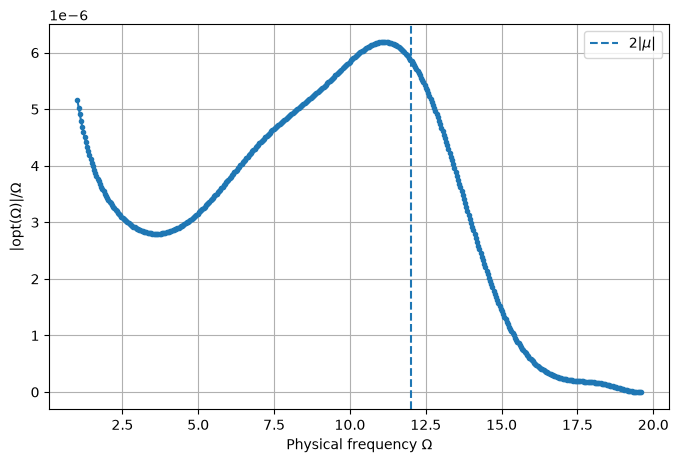

In [62]:
R_avg = 500

Emax = Emax_1

Emin = Emin_1

a = (Emax - Emin) / (2 - 1 / R_avg)

w_scaled = w

w_physical = a * w_scaled



mask = w_physical > 1

plt.figure(figsize=(8, 5))
plt.plot(
    w_physical[mask],
    np.abs(opt[mask]) / w_physical[mask],
    ".-"
)

plt.axvline(2 * abs(mu), linestyle="--", label=r"$2|\mu|$")
plt.xlabel(r"Physical frequency $\Omega$")
plt.ylabel(r"$|\mathrm{opt}(\Omega)|/\Omega$")
plt.grid()
plt.legend()
plt.show()
